In [1]:
print("Weighing the Invisible: Estimating the Mass of Sagittarius A*")

print("My independent investigation of stellar orbits begins here!")

Weighing the Invisible: Estimating the Mass of Sagittarius A*
My independent investigation of stellar orbits begins here!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("All scientific libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SciPy version:", scipy.__version__)

All scientific libraries imported successfully!
NumPy version: 2.4.4
Pandas version: 3.0.6
SciPy version: 1.18.1


In [3]:
from pathlib import Path

project_folder = Path.cwd()

print("Current working directory:")
print(project_folder)

print("\nCSV files found in this folder:")
for file in project_folder.glob("*.csv"):
    print(file.name)
    

Current working directory:
C:\Users\Dr Sunil\DESKTOP\PROJECTS\sagittarius_weight

CSV files found in this folder:


In [4]:
from pathlib import Path

project_folder = Path.cwd()

print("Current working directory:")
print(project_folder)

print("\nCSV files found in this folder:")
for file in project_folder.glob("*.csv"):
    print(file.name)

Current working directory:
C:\Users\Dr Sunil\DESKTOP\PROJECTS\sagittarius_weight

CSV files found in this folder:


In [5]:
from pathlib import Path

project_folder = Path.cwd()

print("Current working directory:")
print(project_folder)

print("\nCSV files found in this folder:")
for file in project_folder.glob("*.csv"):
    print(file.name)

Current working directory:
C:\Users\Dr Sunil\DESKTOP\PROJECTS\sagittarius_weight

CSV files found in this folder:
astrometry_NACO.csv
astrometry_SHARP.csv
velocity_NACO.csv
velocity_OSIRIS.csv
velocity_SINFONI.csv


In [6]:
import pandas as pd

astrometry = pd.read_csv("astrometry_NACO.csv")

print("Dataset dimensions:", astrometry.shape)

print("\nColumn names:")
print(astrometry.columns.tolist())

print("\nFirst five rows:")
display(astrometry.head())

Dataset dimensions: (133, 5)

Column names:
['t', 'x', 'x_err', 'y', 'y_err']

First five rows:


,t,x,x_err,y,y_err
0,2002.2503,0.008122,0.002810,-0.014417,0.002810
1,2002.3351,-0.003988,0.001887,-0.009717,0.001887
2,2002.3927,-0.013654,0.002662,-0.002115,0.002662
3,2002.4085,-0.015542,0.002303,-0.000060,0.002303
4,2002.4115,-0.014656,0.002303,0.000165,0.002303


In [7]:
print("Column names:")
print(astrometry.columns.tolist())

print("\nDataset size:")
print(astrometry.shape)

print("\nData types:")
print(astrometry.dtypes)

print("\nFirst five rows:")
display(astrometry.head())

Column names:
['t', 'x', 'x_err', 'y', 'y_err']

Dataset size:
(133, 5)

Data types:
t        float64
x        float64
x_err    float64
y        float64
y_err    float64
dtype: object

First five rows:


,t,x,x_err,y,y_err
0,2002.2503,0.008122,0.002810,-0.014417,0.002810
1,2002.3351,-0.003988,0.001887,-0.009717,0.001887
2,2002.3927,-0.013654,0.002662,-0.002115,0.002662
3,2002.4085,-0.015542,0.002303,-0.000060,0.002303
4,2002.4115,-0.014656,0.002303,0.000165,0.002303


# 1. Exploring the Astrometric Observations

Astrometry is the measurement of the positions and apparent motion of celestial objects across the sky.

In this investigation, we use astrometric observations to study the motion of a star near Sagittarius A*, the compact object at the centre of the Milky Way.

The dataset contains 133 observations, each recording the observation time, two position coordinates, and the corresponding measurement uncertainties.

Before constructing an orbital model, we first visualise the observed positions and examine their uncertainties.

This initial analysis helps us understand the data and identify any issues that need to be addressed before fitting an orbit.

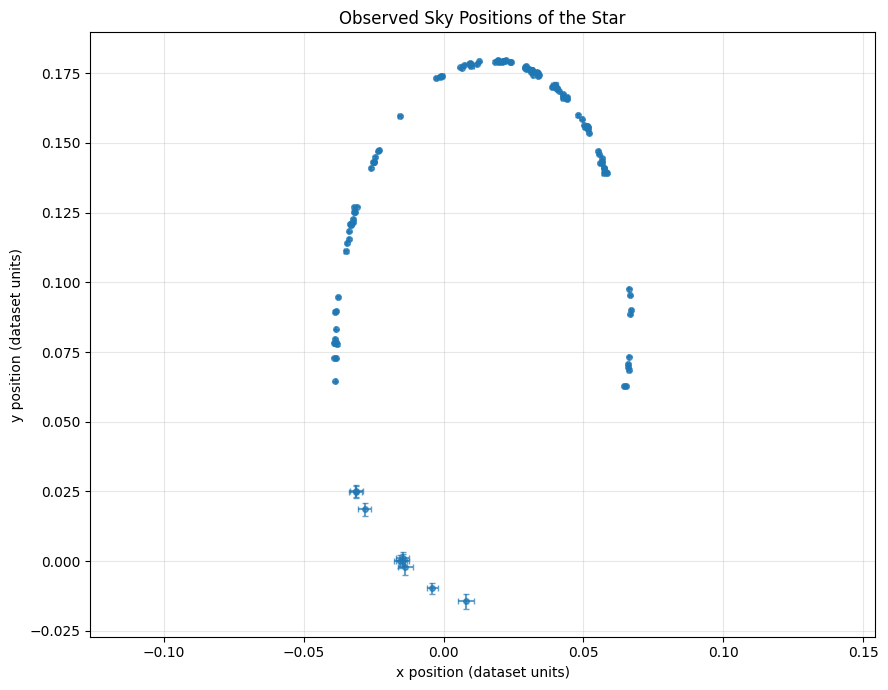

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Sort observations by time
astrometry = astrometry.sort_values("t").reset_index(drop=True)

# Plot the measured positions
plt.figure(figsize=(9, 7))

plt.errorbar(
    astrometry["x"],
    astrometry["y"],
    xerr=astrometry["x_err"],
    yerr=astrometry["y_err"],
    fmt="o",
    markersize=4,
    capsize=2,
    alpha=0.7
)

plt.xlabel("x position (dataset units)")
plt.ylabel("y position (dataset units)")
plt.title("Observed Sky Positions of the Star")
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

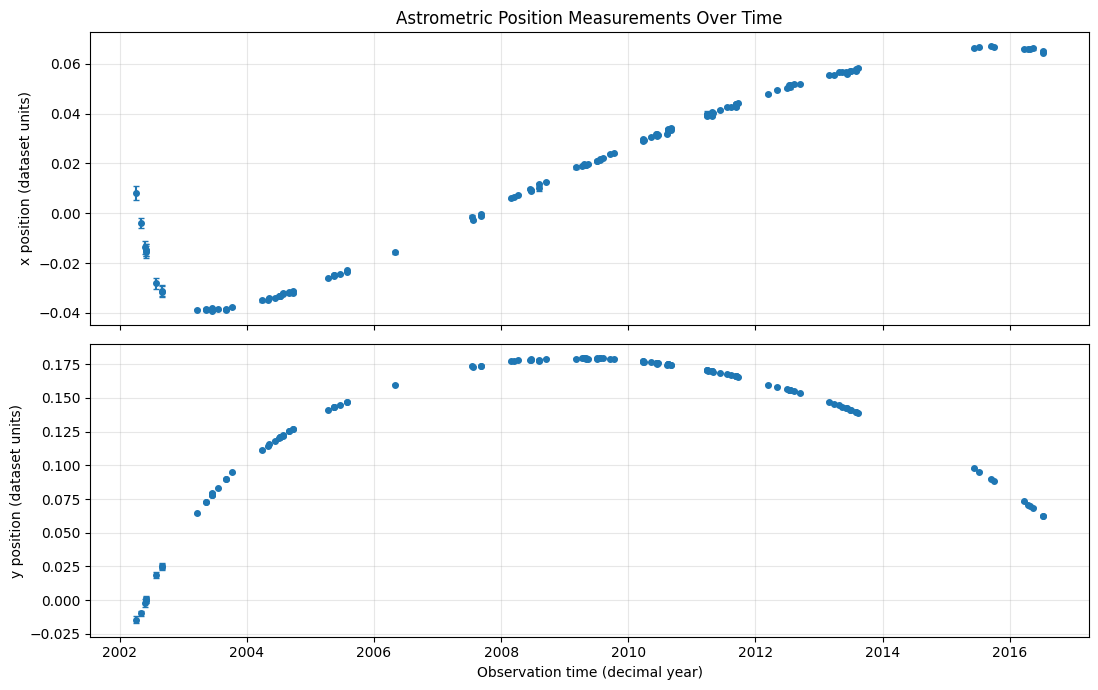

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].errorbar(
    astrometry["t"],
    astrometry["x"],
    yerr=astrometry["x_err"],
    fmt="o",
    markersize=4,
    capsize=2
)

axes[0].set_ylabel("x position (dataset units)")
axes[0].set_title("Astrometric Position Measurements Over Time")
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    astrometry["t"],
    astrometry["y"],
    yerr=astrometry["y_err"],
    fmt="o",
    markersize=4,
    capsize=2
)

axes[1].set_xlabel("Observation time (decimal year)")
axes[1].set_ylabel("y position (dataset units)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

readme_path = Path("README.md")

if readme_path.exists():
    print(readme_path.read_text(encoding="utf-8")[:12000])
else:
    print("README.md was not found in the current directory.")

# Stellar Orbit Fitting

Fit the orbit of the star S2 moving around the black hole at the center of the
Milky Way:

_[Example Notebook](example.ipynb)_

[![](preview.png)](https://github.com/pmplewa/GC-OrbitFit/blob/master/example.ipynb)

This code takes into account first-order post-Newtonian corrections and
gravitational redshift, as well as a time-correlated astrometric noise
component. For the most part it is written with readability in mind, not
performance.

Please also note that the latest version of this code implements **nested
sampling** based on _[dynesty]_, while earlier versions implemented MCMC
sampling based on _[emcee]_.

To install the latest development version, run:

    pip install git+https://github.com/pmplewa/GC-OrbitFit.git

To set up a complete development environment instead, install [uv] and run:

    git clone https://github.com/pmplewa/GC-OrbitFit.git
    cd GC-OrbitFit
    uv sync --all-extras --dev

At the time of writing, on Linux systems, the package _r

In [12]:
print("Observation time range:")
print("First observation:", astrometry["t"].min())
print("Last observation:", astrometry["t"].max())

print("\nNumber of observations:", len(astrometry))

print("\nMissing values:")
print(astrometry.isnull().sum())

print("\nCoordinate ranges:")
print("x:", astrometry["x"].min(), "to", astrometry["x"].max())
print("y:", astrometry["y"].min(), "to", astrometry["y"].max())

print("\nUncertainty ranges:")
print("x_err:", astrometry["x_err"].min(), "to", astrometry["x_err"].max())
print("y_err:", astrometry["y_err"].min(), "to", astrometry["y_err"].max())

Observation time range:
First observation: 2002.2503
Last observation: 2016.5302

Number of observations: 133

Missing values:
t        0
x        0
x_err    0
y        0
y_err    0
dtype: int64

Coordinate ranges:
x: -0.039112 to 0.066975
y: -0.014417 to 0.17955

Uncertainty ranges:
x_err: 0.000216 to 0.00281
y_err: 0.000215 to 0.00281


# 2. Visualising the Observed Stellar Motion

The astrometric dataset contains 133 measurements collected between 2002 and 2016.

Each observation records the apparent position of S2 along two perpendicular sky-coordinate axes.

Plotting these positions allows us to inspect the observed trajectory before constructing an orbital model.

The error bars represent the reported measurement uncertainties. They help us assess how precisely each position has been determined.

Because the observations cover only a finite period and the measurements have different uncertainties, we must fit a physical model rather than assume that the plotted points define a perfect ellipse.

In [14]:
from pathlib import Path

for filename in [
    "velocity_NACO.csv",
    "velocity_OSIRIS.csv",
    "velocity_SINFONI.csv"
]:
    path = Path(filename)

    if path.exists():
        data = pd.read_csv(path)

        print(f"\n{'=' * 50}")
        print("File:", filename)
        print("Dimensions:", data.shape)
        print("Columns:", data.columns.tolist())
        display(data.head())
    else:
        print(f"\nFile not found in current directory: {filename}")


File: velocity_NACO.csv
Dimensions: (2, 3)
Columns: ['t', 'vz', 'vz_err']


,t,vz,vz_err
0,2003.3532,-1512.0,35.0
1,2003.4463,-1428.0,45.0



File: velocity_OSIRIS.csv
Dimensions: (3, 3)
Columns: ['t', 'vz', 'vz_err']


,t,vz,vz_err
0,2000.4870,1199.0,100.0
1,2002.4175,-495.0,36.0
2,2002.4205,-532.0,44.0



File: velocity_SINFONI.csv
Dimensions: (39, 3)
Columns: ['t', 'vz', 'vz_err']


,t,vz,vz_err
0,2003.2711,-1571.0,52.0
1,2004.5351,-1055.0,41.0
2,2004.5370,-1056.0,33.0
3,2004.6320,-1039.0,34.0
4,2005.1579,-1001.0,68.0


In [15]:
import pandas as pd
import matplotlib.pyplot as plt

velocity_files = [
    "velocity_NACO.csv",
    "velocity_OSIRIS.csv",
    "velocity_SINFONI.csv"
]

velocity_data = []

for filename in velocity_files:
    data = pd.read_csv(filename)
    data["instrument"] = filename.replace(".csv", "")
    velocity_data.append(data)

velocity = pd.concat(velocity_data, ignore_index=True)
velocity = velocity.sort_values("t").reset_index(drop=True)

print("Total radial-velocity observations:", len(velocity))
print("\nObservations by instrument:")
print(velocity["instrument"].value_counts())

display(velocity.head())

Total radial-velocity observations: 44

Observations by instrument:
instrument
velocity_SINFONI    39
velocity_OSIRIS      3
velocity_NACO        2
Name: count, dtype: int64


,t,vz,vz_err,instrument
0,2000.4870,1199.0,100.0,velocity_OSIRIS
1,2002.4175,-495.0,36.0,velocity_OSIRIS
2,2002.4205,-532.0,44.0,velocity_OSIRIS
3,2003.2711,-1571.0,52.0,velocity_SINFONI
4,2003.3532,-1512.0,35.0,velocity_NACO


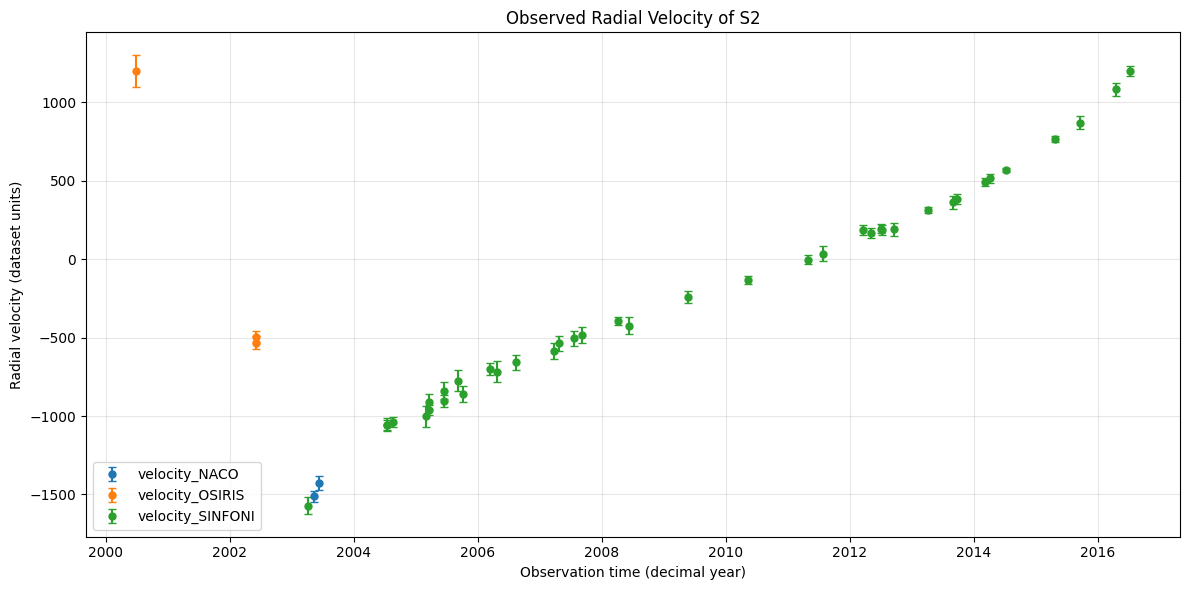

In [16]:
plt.figure(figsize=(12, 6))

for instrument, group in velocity.groupby("instrument"):
    plt.errorbar(
        group["t"],
        group["vz"],
        yerr=group["vz_err"],
        fmt="o",
        markersize=5,
        capsize=3,
        label=instrument
    )

plt.xlabel("Observation time (decimal year)")
plt.ylabel("Radial velocity (dataset units)")
plt.title("Observed Radial Velocity of S2")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
plt.savefig("velocity_plot.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [18]:
print(velocity.describe())
print("\nObservations by instrument:")
print(velocity["instrument"].value_counts())

                 t           vz      vz_err
count    44.000000    44.000000   44.000000
mean   2008.748550  -264.159091   41.068182
std       4.439339   729.854173   15.564416
min    2000.487000 -1571.000000   15.000000
25%    2005.214400  -844.250000   30.000000
50%    2007.611350  -453.500000   40.000000
75%    2012.561225   224.500000   50.000000
max    2016.519100  1199.000000  100.000000

Observations by instrument:
instrument
velocity_SINFONI    39
velocity_OSIRIS      3
velocity_NACO        2
Name: count, dtype: int64


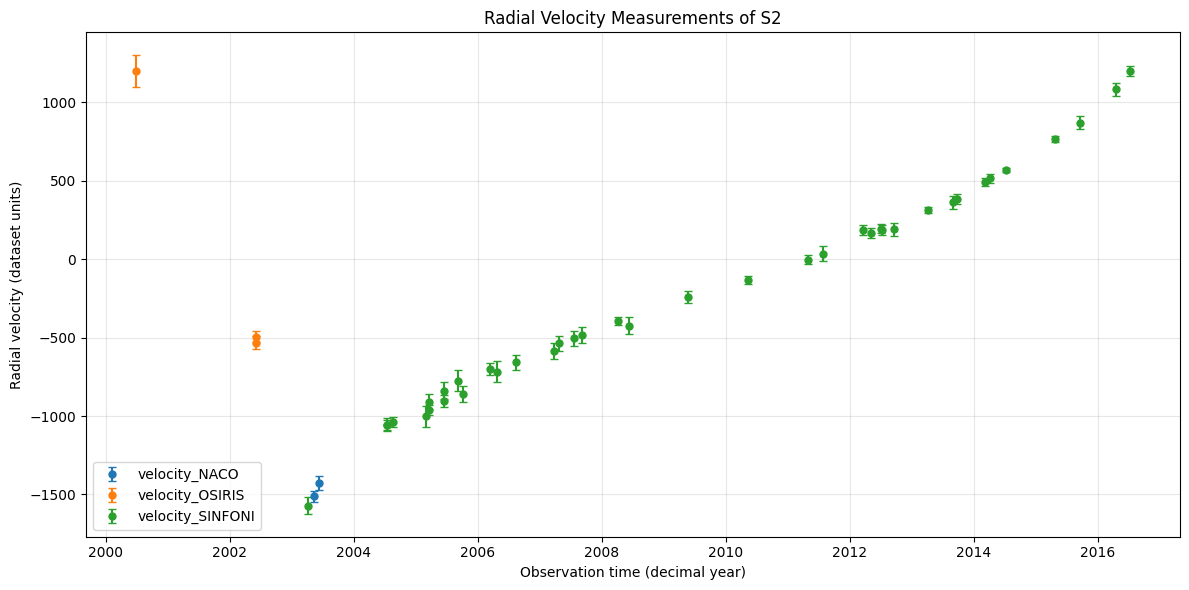

In [19]:
plt.figure(figsize=(12, 6))

for instrument, group in velocity.groupby("instrument"):
    plt.errorbar(
        group["t"],
        group["vz"],
        yerr=group["vz_err"],
        fmt="o",
        markersize=5,
        capsize=3,
        label=instrument
    )

plt.xlabel("Observation time (decimal year)")
plt.ylabel("Radial velocity (dataset units)")
plt.title("Radial Velocity Measurements of S2")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
import json
from pathlib import Path

p = Path("example.ipynb")
nb = json.loads(p.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell["source"])

    if cell["cell_type"] == "markdown":
        print(f"\n--- Markdown cell {i} ---")
        print(source[:1500])

    elif any(word in source.lower() for word in [
        "arcsec", "distance", "velocity", "mas",
        "orbit", "semimajor", "solar", "read_csv"
    ]):
        print(f"\n--- Code cell {i} ---")
        print(source[:1200])


--- Code cell 0 ---
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dynesty import plotting as dyplot

from gc_orbitfit.data import load_sample_data
from gc_orbitfit.fitting import LBFGSBFitter
from gc_orbitfit.gp_tools import sample_gp
from gc_orbitfit.models import GaussianNoiseModel, GPNoiseModel, predict_resid
from gc_orbitfit.plotting import plot_data, plot_resid
from gc_orbitfit.priors import UniformPrior
from gc_orbitfit.sampling import NestedSampler

warnings.filterwarnings("ignore")

--- Code cell 6 ---
model_a = GaussianNoiseModel()
sampler_a = NestedSampler(data, names_a, priors_a, model_a)
worker_a = sampler_a.sample_orbit(sampler_kwargs=opts, checkpoint="run_a.sav")
worker_a.results.summary()

--- Code cell 7 ---
model_b = GPNoiseModel()
sampler_b = NestedSampler(data, names_b, priors_b, model_b)
worker_b = sampler_b.sample_orbit(sampler_kwargs=opts, checkpoint="run_b.sav")
samples_b = worker_b.results.samples_equal(rstate=rng)

In [22]:
for i, cell in enumerate(nb["cells"]):
    source = "".join(cell["source"])

    if i in [1, 2, 3, 4, 5]:
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(source)


==================== CELL 1 ====================
rng = np.random.default_rng()

==================== CELL 2 ====================
data = load_sample_data()

==================== CELL 3 ====================
plot_data(data)
plt.tight_layout()
plt.show()

==================== CELL 4 ====================
# GPNoiseModel
names_b, priors_b = zip(
    *[
        ("M0", UniformPrior(3, 5)),
        ("R0", UniformPrior(7, 9)),
        ("a", UniformPrior(0.10, 0.15)),
        ("e", UniformPrior(0.87, 0.90)),
        ("inc", UniformPrior(2.3, 2.5)),
        ("Omega", UniformPrior(3.9, 4.1)),
        ("omega", UniformPrior(1.0, 1.2)),
        ("tp", UniformPrior(2002.1, 2002.5)),
        ("x0", UniformPrior(-5e-3, 5e-3)),
        ("y0", UniformPrior(-5e-3, 5e-3)),
        ("vx0", UniformPrior(-1e-3, 1e-3)),
        ("vy0", UniformPrior(-1e-3, 1e-3)),
        ("vz0", UniformPrior(-50, 50)),
        ("log_s2", UniformPrior(np.log(0.01e-6), np.log(1e-3))),
        ("log_taux", UniformPrior(np.log(0.01

In [23]:
```python
import inspect
from gc_orbitfit.data import load_sample_data

print(inspect.getsource(load_sample_data))
```


SyntaxError: invalid syntax (564992960.py, line 1)

In [24]:
import inspect
from gc_orbitfit.data import load_sample_data

print(inspect.getsource(load_sample_data))

ModuleNotFoundError: No module named 'gc_orbitfit'

In [25]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())

Current folder: C:\Users\Dr Sunil\DESKTOP\PROJECTS\sagittarius_weight

Files in current folder:
['.ipynb_checkpoints', 'astrometry_NACO.csv', 'astrometry_SHARP.csv', 'desktop.ini', 'example.ipynb', 'GC-OrbitFit-main', 'pyproject.toml', 'README.md', 'velocity_NACO.csv', 'velocity_OSIRIS.csv', 'velocity_plot.png', 'velocity_SINFONI.csv', 'weighing_the_invisible.ipynb']


In [26]:
import inspect
from gc_orbitfit.data import load_sample_data

print(inspect.getsource(load_sample_data))

ModuleNotFoundError: No module named 'gc_orbitfit'

In [27]:
import os

for root, dirs, files in os.walk("GC-OrbitFit-main"):
    if "gc_orbitfit" in dirs:
        print("Package found at:", os.path.join(root, "gc_orbitfit"))
    if "pyproject.toml" in files:
        print("Project configuration:", os.path.join(root, "pyproject.toml"))

Package found at: GC-OrbitFit-main\gc_orbitfit


In [28]:
from pathlib import Path

print(Path("README.md").read_text(encoding="utf-8")[:5000])

# Stellar Orbit Fitting

Fit the orbit of the star S2 moving around the black hole at the center of the
Milky Way:

_[Example Notebook](example.ipynb)_

[![](preview.png)](https://github.com/pmplewa/GC-OrbitFit/blob/master/example.ipynb)

This code takes into account first-order post-Newtonian corrections and
gravitational redshift, as well as a time-correlated astrometric noise
component. For the most part it is written with readability in mind, not
performance.

Please also note that the latest version of this code implements **nested
sampling** based on _[dynesty]_, while earlier versions implemented MCMC
sampling based on _[emcee]_.

To install the latest development version, run:

    pip install git+https://github.com/pmplewa/GC-OrbitFit.git

To set up a complete development environment instead, install [uv] and run:

    git clone https://github.com/pmplewa/GC-OrbitFit.git
    cd GC-OrbitFit
    uv sync --all-extras --dev

At the time of writing, on Linux systems, the package _r

In [29]:
import sys
import os

repo_path = os.path.abspath("GC-OrbitFit-main")
sys.path.insert(0, repo_path)

from gc_orbitfit.data import load_sample_data
import inspect

print(inspect.getsource(load_sample_data))

def load_sample_data(
    prefix: str = "https://github.com/pmplewa/GC-OrbitFit/raw/main/",
) -> pd.DataFrame:
    """Load the default data set."""
    pos_data = pd.concat(
        [
            load_astrometry(f"{prefix}astrometry_SHARP.csv", instrument="SHARP"),
            load_astrometry(f"{prefix}astrometry_NACO.csv", instrument="NACO"),
        ]
    )

    vel_data = pd.concat(
        [
            load_velocity(f"{prefix}velocity_NACO.csv", instrument="NACO"),
            load_velocity(f"{prefix}velocity_OSIRIS.csv", instrument="OSIRIS"),
            load_velocity(f"{prefix}velocity_SINFONI.csv", instrument="SINFONI"),
        ]
    )

    assert len(pos_data) == 145, "Unexpected number of astrometric data points."
    assert len(vel_data) == 44, "Unexpected number of velocity data points."

    return pd.concat([pos_data, vel_data]).sort_index()



In [31]:
import inspect
from gc_orbitfit.data import load_astrometry, load_velocity

print("========== ASTROMETRY LOADER ==========")
print(inspect.getsource(load_astrometry))

print("\n========== VELOCITY LOADER ==========")
print(inspect.getsource(load_velocity))

========== ASTROMETRY LOADER ==========
def load_astrometry(
    path: str | PathLike, instrument: str, rescale: float | None = None
) -> pd.DataFrame:
    data = pd.read_csv(path, index_col=0)
    data["instrument"] = instrument
    if rescale is not None:
        # rescale all error bars
        data[["x_err", "y_err"]] *= rescale
    if instrument == "SHARP":
        # speckle imaging
        data["technique"] = "imaging"
        # ... allow for preprocessing of the input data
        return data
    if instrument == "NACO":
        # adaptive optics imaging
        data["technique"] = "imaging"
        return data
    if instrument == "GRAVITY":
        # single field interferometry
        data["technique"] = "interferometry"
        return data
    raise ValueError(f"Unknown instrument '{instrument}'.")


========== VELOCITY LOADER ==========
def load_velocity(path: str | PathLike, instrument: str) -> pd.DataFrame:
    data = pd.read_csv(path, index_col=0)
    data["instrument"] 

In [32]:
from pathlib import Path

print(Path("GC-OrbitFit-main/pyproject.toml").read_text(encoding="utf-8"))

FileNotFoundError: [Errno 2] No such file or directory: 'GC-OrbitFit-main\\pyproject.toml'